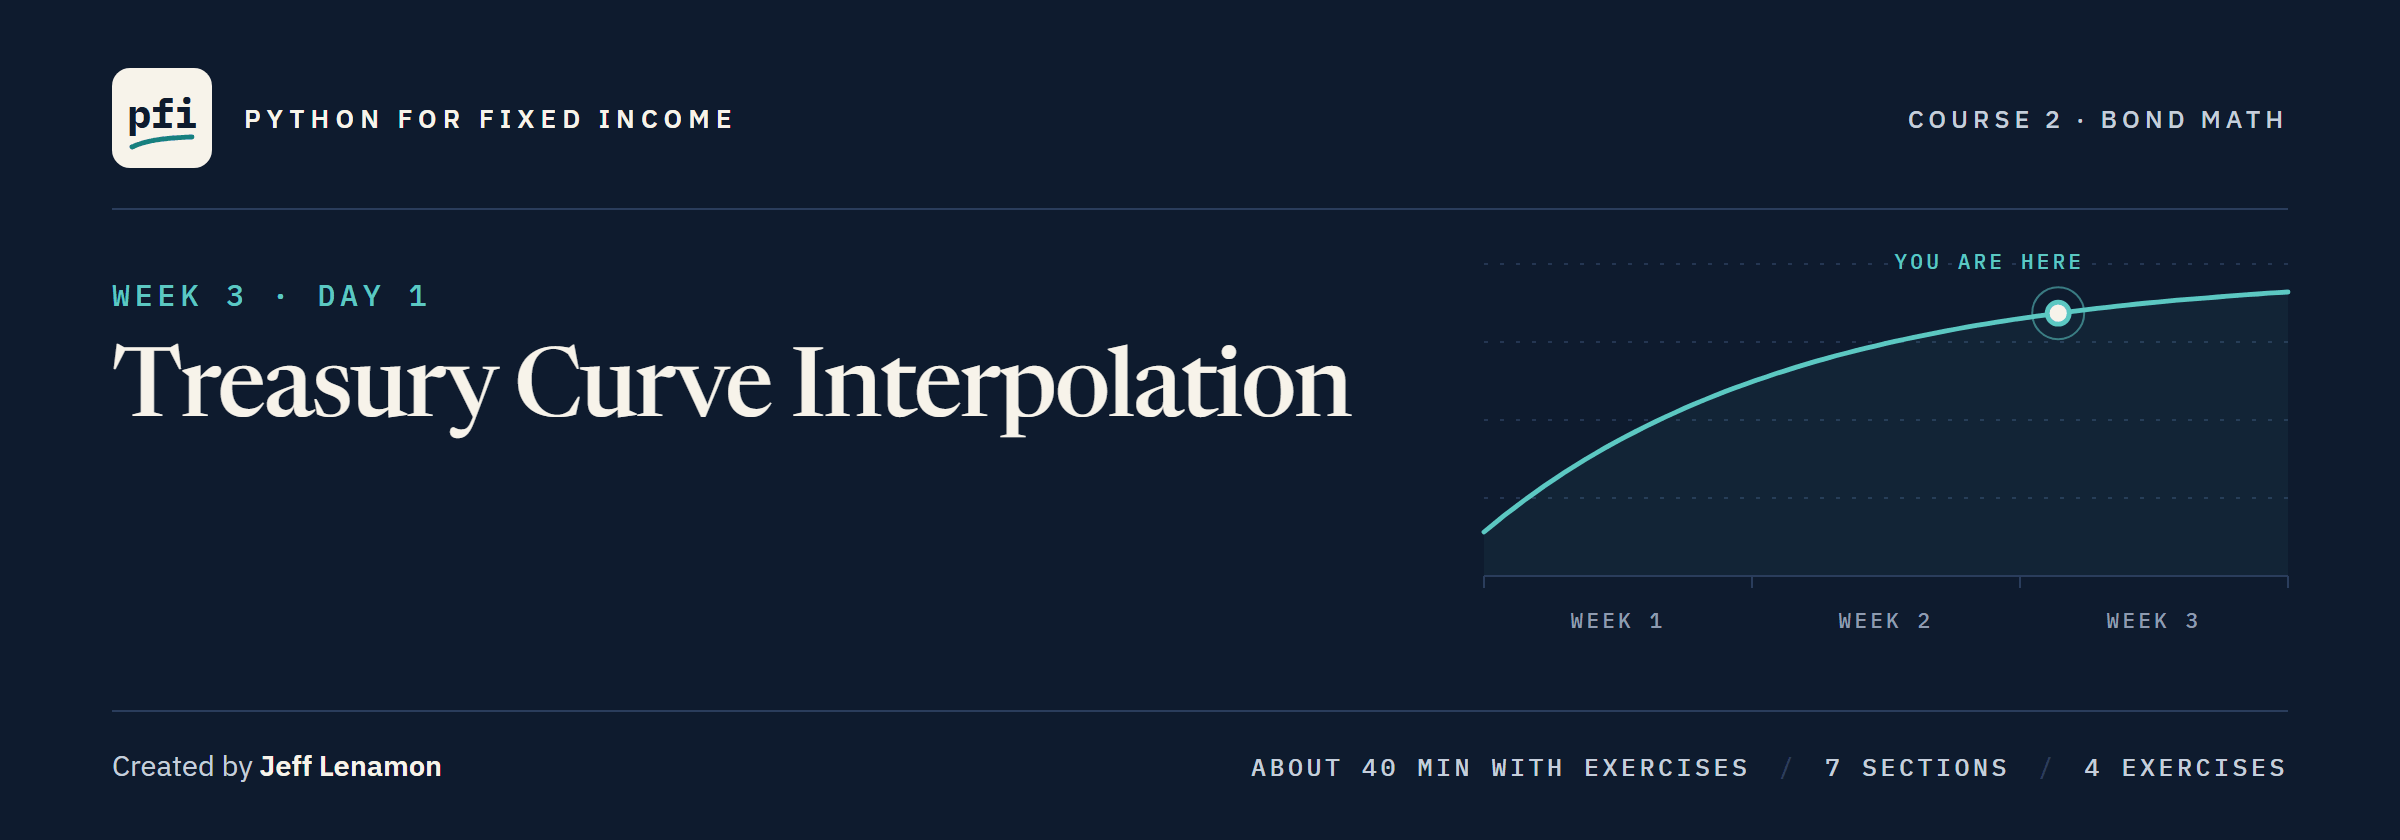

# Treasury Curve Interpolation

Week 3, Day 1. A yield at any maturity from a curve published at a few tenors: a straight line between two of them, `interpolate_yield` in the module, tied to Excel, and what the straight line misses.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week3/day1/11_treasury_curve_interpolation.ipynb)

### The Desk Lead's Note

> Week 3 measures every bond against Treasuries, so each bond needs a Treasury yield at its own maturity. Treasury publishes fourteen tenors. Read me the 30 September curve at 6.4 years, then put the method in `bondmath` and tie it to Excel. Tell me which curve our holdings were built on, and how much a straight line between tenors moves the number.

Every statement today describes the data; none says where yields go.

### The Data

Two curves arrive in the work folder today, each with one job.

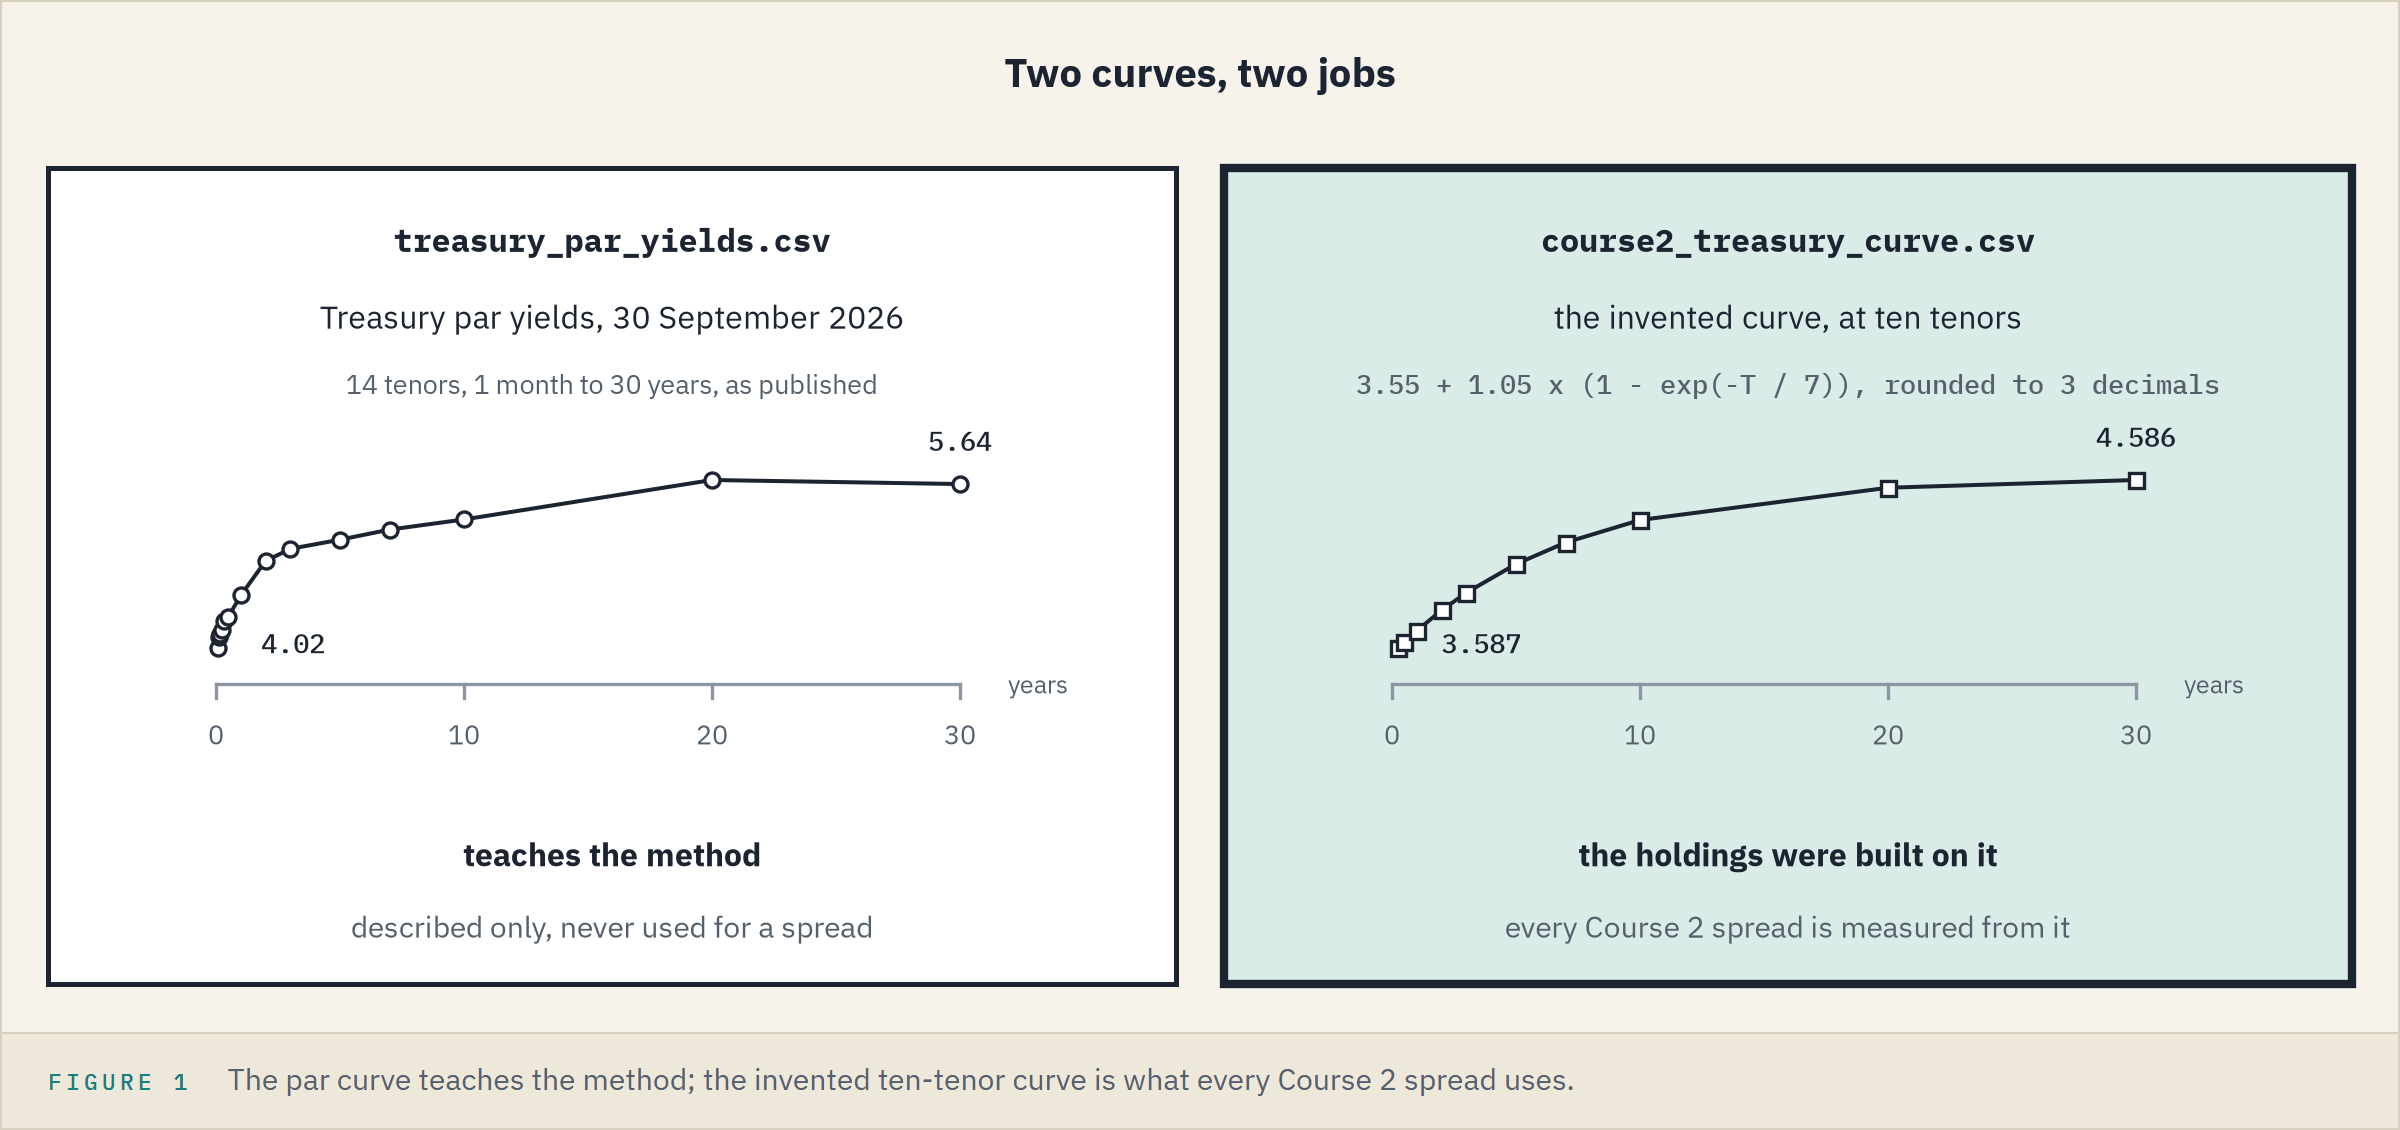

<table align="left">
<tr><th align="left">Treasury's file</th><th align="left"></th></tr>
<tr><td align="left">Source</td><td align="left">U.S. Department of the Treasury, <a href="https://home.treasury.gov/resource-center/data-chart-center/interest-rates/TextView?type=daily_treasury_yield_curve">Daily Treasury Par Yield Curve Rates</a></td></tr>
<tr><td align="left">Retrieved</td><td align="left">2026-10-03, from the yearly CSV downloads</td></tr>
<tr><td align="left">Reuse</td><td align="left">public domain, CC0 1.0, in <a href="https://www.treasury.gov/jsonfiles/data.json">Treasury's data inventory</a></td></tr>
</table>
<br clear="left">

Treasury describes the series as par yields based on closing bid prices of the most recently auctioned securities ([its description](https://home.treasury.gov/policy-issues/financing-the-government/interest-rate-statistics)): percent, two decimals, as published.
`course2_treasury_curve.csv` is invented, a smooth formula at ten tenors, and is the curve the holdings file was built on.

**The real curve teaches the method; the invented one is the one Course 2 measures from.**

### Today's Work Folder

Q. Where does today's work happen?

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module, its tests, and its Git history
# as notebook 10 left them.
# To start the day again, restart the kernel and run all cells.
work = start_day(11)

Work folder pfi_course2_11_k4w7q2xr: 4 data files, the module as notebook 10 left it, 10 commits, tagged week1 and week2


### The Tests Pass Before We Start

In [2]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

............................                                             [100%]
28 passed in 0.50s



### Imports

In [3]:
import importlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# the house greens and greys, as in Course 1's Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])
import bondmath

## Your Route Through Day 1

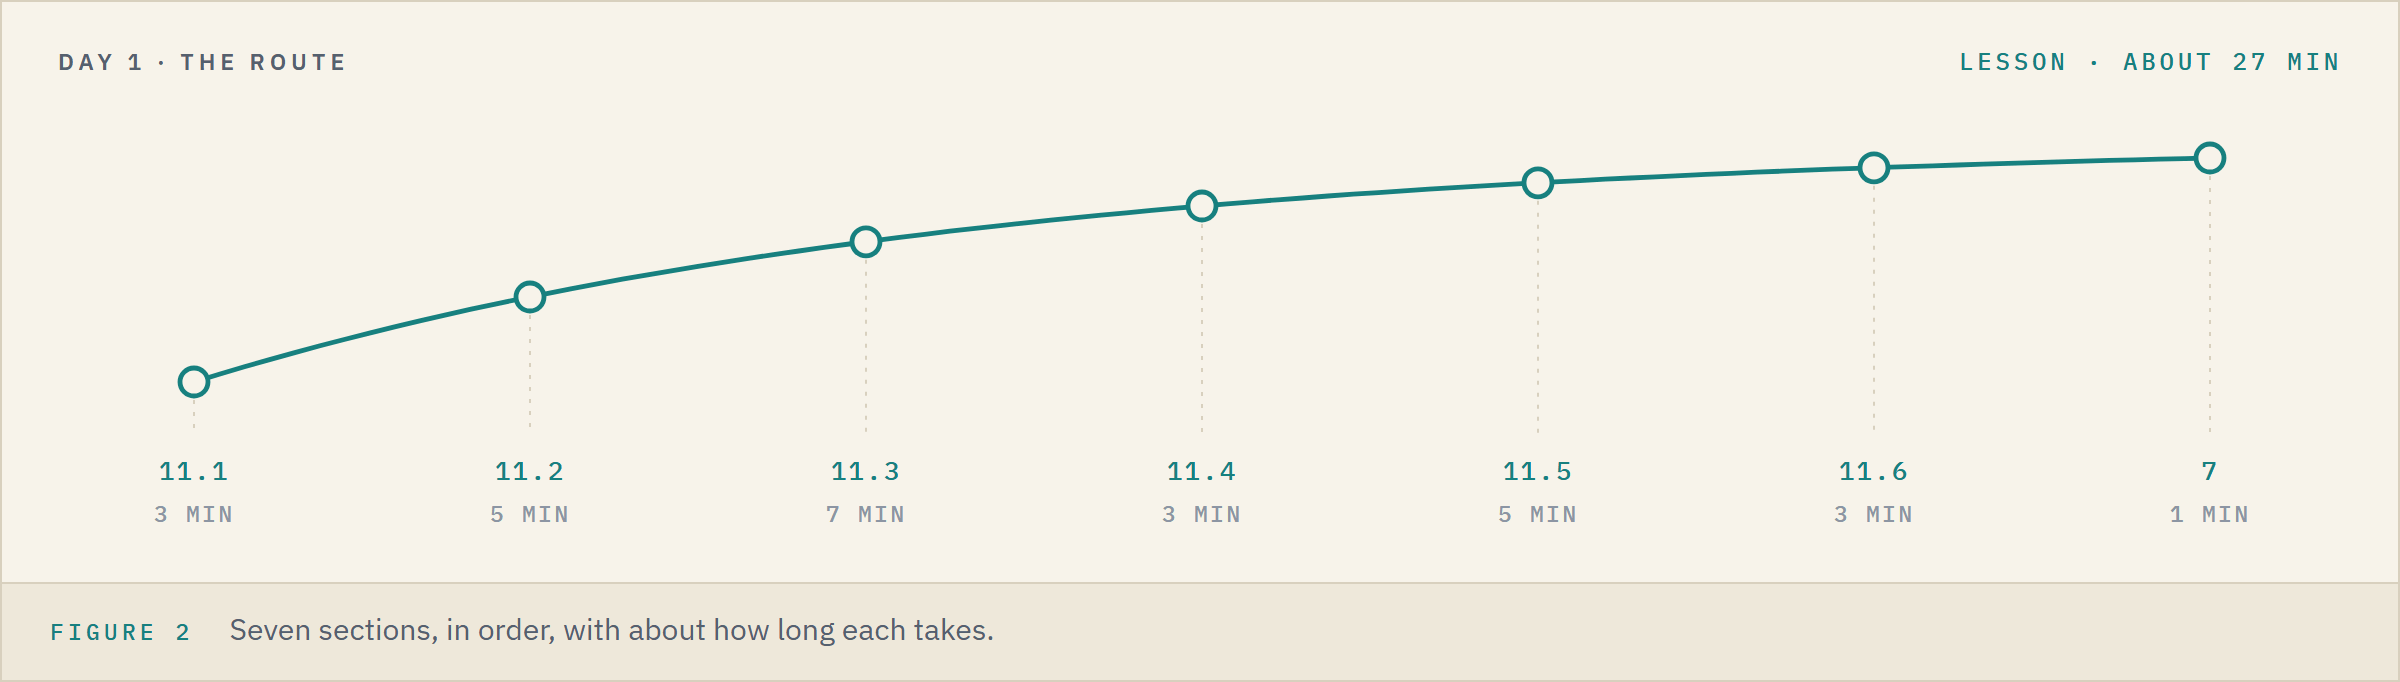

<table align="left">
<tr><th align="left"></th><th align="left">Section</th><th align="left">About</th></tr>
<tr><td align="left">11.1</td><td align="left">The Curve on 30 September 2026</td><td align="left">3 min</td></tr>
<tr><td align="left">11.2</td><td align="left">A Straight Line Between Two Tenors</td><td align="left">5 min</td></tr>
<tr><td align="left">11.3</td><td align="left"><code>interpolate_yield</code>, Docstring First</td><td align="left">7 min</td></tr>
<tr><td align="left">11.4</td><td align="left">The Same With <code>numpy.interp</code></td><td align="left">3 min</td></tr>
<tr><td align="left">11.5</td><td align="left">The Curve the Holdings Were Built On</td><td align="left">5 min</td></tr>
<tr><td align="left">11.6</td><td align="left">How Far the Straight Line Sits From the Smooth Curve</td><td align="left">3 min</td></tr>
<tr><td align="left">7</td><td align="left">Bring It Home</td><td align="left">1 min</td></tr>
</table>
<br clear="left">

**Time.** About 27 minutes for the lesson, then about 12 for the four exercises.

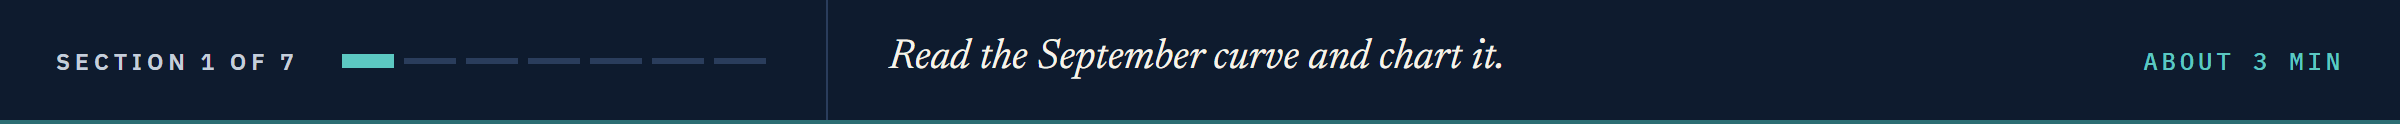

## 11.1 The Curve on 30 September 2026

### One Row of Treasury's File

Q. What did the curve read on 30 September 2026?

In [4]:
# the dates become the row labels, as in Course 1's Treasury case study
treasury = pd.read_csv('treasury_par_yields.csv', index_col='date')
curve_row = treasury.loc['2026-09-30']
curve_row

1 Mo         4.02
1.5 Month    4.13
2 Mo         4.16
3 Mo         4.20
4 Mo         4.29
6 Mo         4.33
1 Yr         4.54
2 Yr         4.88
3 Yr         5.00
5 Yr         5.09
7 Yr         5.19
10 Yr        5.29
20 Yr        5.68
30 Yr        5.64
Name: 2026-09-30, dtype: float64

Fourteen yields in percent, under text labels: `Mo` for most month tenors, `Month` for the 1.5-month one.
A label cannot go on an axis or into a formula; a tenor in years can.

### Labels Into Years

In [5]:
# each label's length in years, typed once, as in Course 1's Treasury case study
tenor_years = {'1 Mo': 1 / 12, '1.5 Month': 1.5 / 12, '2 Mo': 2 / 12, '3 Mo': 3 / 12,
               '4 Mo': 4 / 12, '6 Mo': 0.5, '1 Yr': 1, '2 Yr': 2, '3 Yr': 3, '5 Yr': 5,
               '7 Yr': 7, '10 Yr': 10, '20 Yr': 20, '30 Yr': 30}
real_curve = pd.DataFrame({'label': curve_row.index, 'yield_pct': curve_row.values})
real_curve['tenor_years'] = [tenor_years[label] for label in real_curve['label']]
real_curve.style.format({'yield_pct': '{:.2f}', 'tenor_years': '{:.4f}'}).background_gradient(
    subset=['yield_pct'], cmap='Greens')

,label,yield_pct,tenor_years
0,1 Mo,4.02,0.0833
1,1.5 Month,4.13,0.1250
2,2 Mo,4.16,0.1667
3,3 Mo,4.20,0.2500
4,4 Mo,4.29,0.3333
5,6 Mo,4.33,0.5000
6,1 Yr,4.54,1.0000
7,2 Yr,4.88,2.0000
8,3 Yr,5.00,3.0000
9,5 Yr,5.09,5.0000


6 of the 14 tenors are under a year; the last two are 10 years apart.

### Fourteen Points at Their Distances

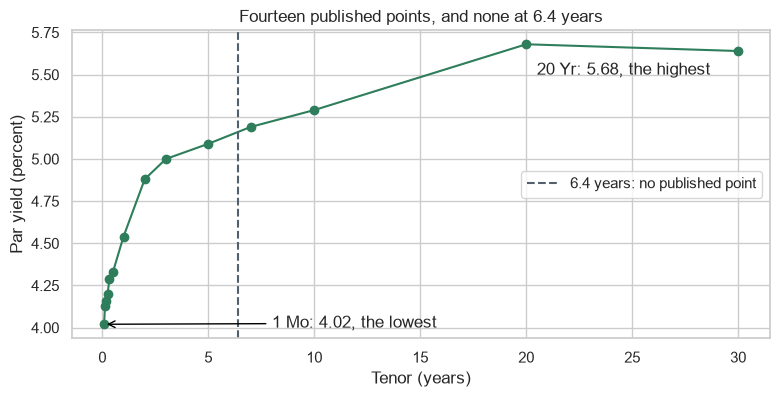

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(real_curve['tenor_years'], real_curve['yield_pct'], marker='o')
ax.axvline(6.4, color='#52606D', linestyle='--', label='6.4 years: no published point')
ax.annotate('1 Mo: 4.02, the lowest', xy=(1 / 12, 4.02), xytext=(8, 4.0),
            arrowprops={'arrowstyle': '->', 'color': 'black'})
ax.text(20.5, 5.5, '20 Yr: 5.68, the highest')
ax.set_title('Fourteen published points, and none at 6.4 years')
ax.set_xlabel('Tenor (years)')
ax.set_ylabel('Par yield (percent)')
ax.legend(loc='center right')
plt.show()

The `20 Yr` sat above the `30 Yr`, 5.68 against 5.64, as Course 1's Treasury case study found on its last date.
The chart describes one date; it says nothing about why the curve had this shape or where it goes.

**Excel side by side.** Tenors in years in A2:A15 (`=1/12` for `1 Mo`, and so on), yields in B2:B15.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Chart the curve</td><td align="left"><code>ax.plot(..., marker='o')</code></td><td align="left">select A1:B15, Insert, Scatter with Straight Lines and Markers</td><td align="left">one series, <code>yield_pct</code>, tenors in years on the x axis</td></tr>
<tr><td align="left">The same range as a Line chart</td><td align="left">(none)</td><td align="left">select A1:B15, Insert, Line</td><td align="left">two series, the tenor column drawn as a line, 14 points evenly spaced</td></tr>
</table>
<br clear="left">

**Fourteen points and none at 6.4 years: the yield there comes from a line drawn between two of them.**

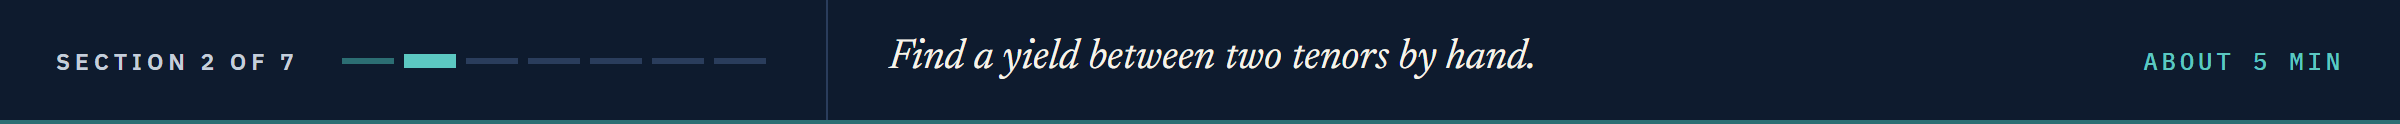

## 11.2 A Straight Line Between Two Tenors

6.4 years lies between the 5-year and the 7-year tenors: they are its **bracket**.
**Linear interpolation** reads the straight line between them.
Its pieces: the left and right tenors, their yields, and the **weight**, the share of the way from the left tenor to the right one.

**Predict 1**

Q. On 30 September 2026 the 5-year yielded 5.09 percent and the 7-year 5.19. Read a straight line between them at 6.4 years. Write down a number.

### By Hand

In [7]:
left_tenor, right_tenor = 5, 7
left_yield, right_yield = curve_row['5 Yr'], curve_row['7 Yr']
# the share of the way from 5 years to 7 at which 6.4 years lies
weight = (6.4 - left_tenor) / (right_tenor - left_tenor)
yield_at_tenor = left_yield + weight * (right_yield - left_yield)
print(f'weight {weight:.1f}: {yield_at_tenor:.4f} percent at 6.4 years')

weight 0.7: 5.1600 percent at 6.4 years


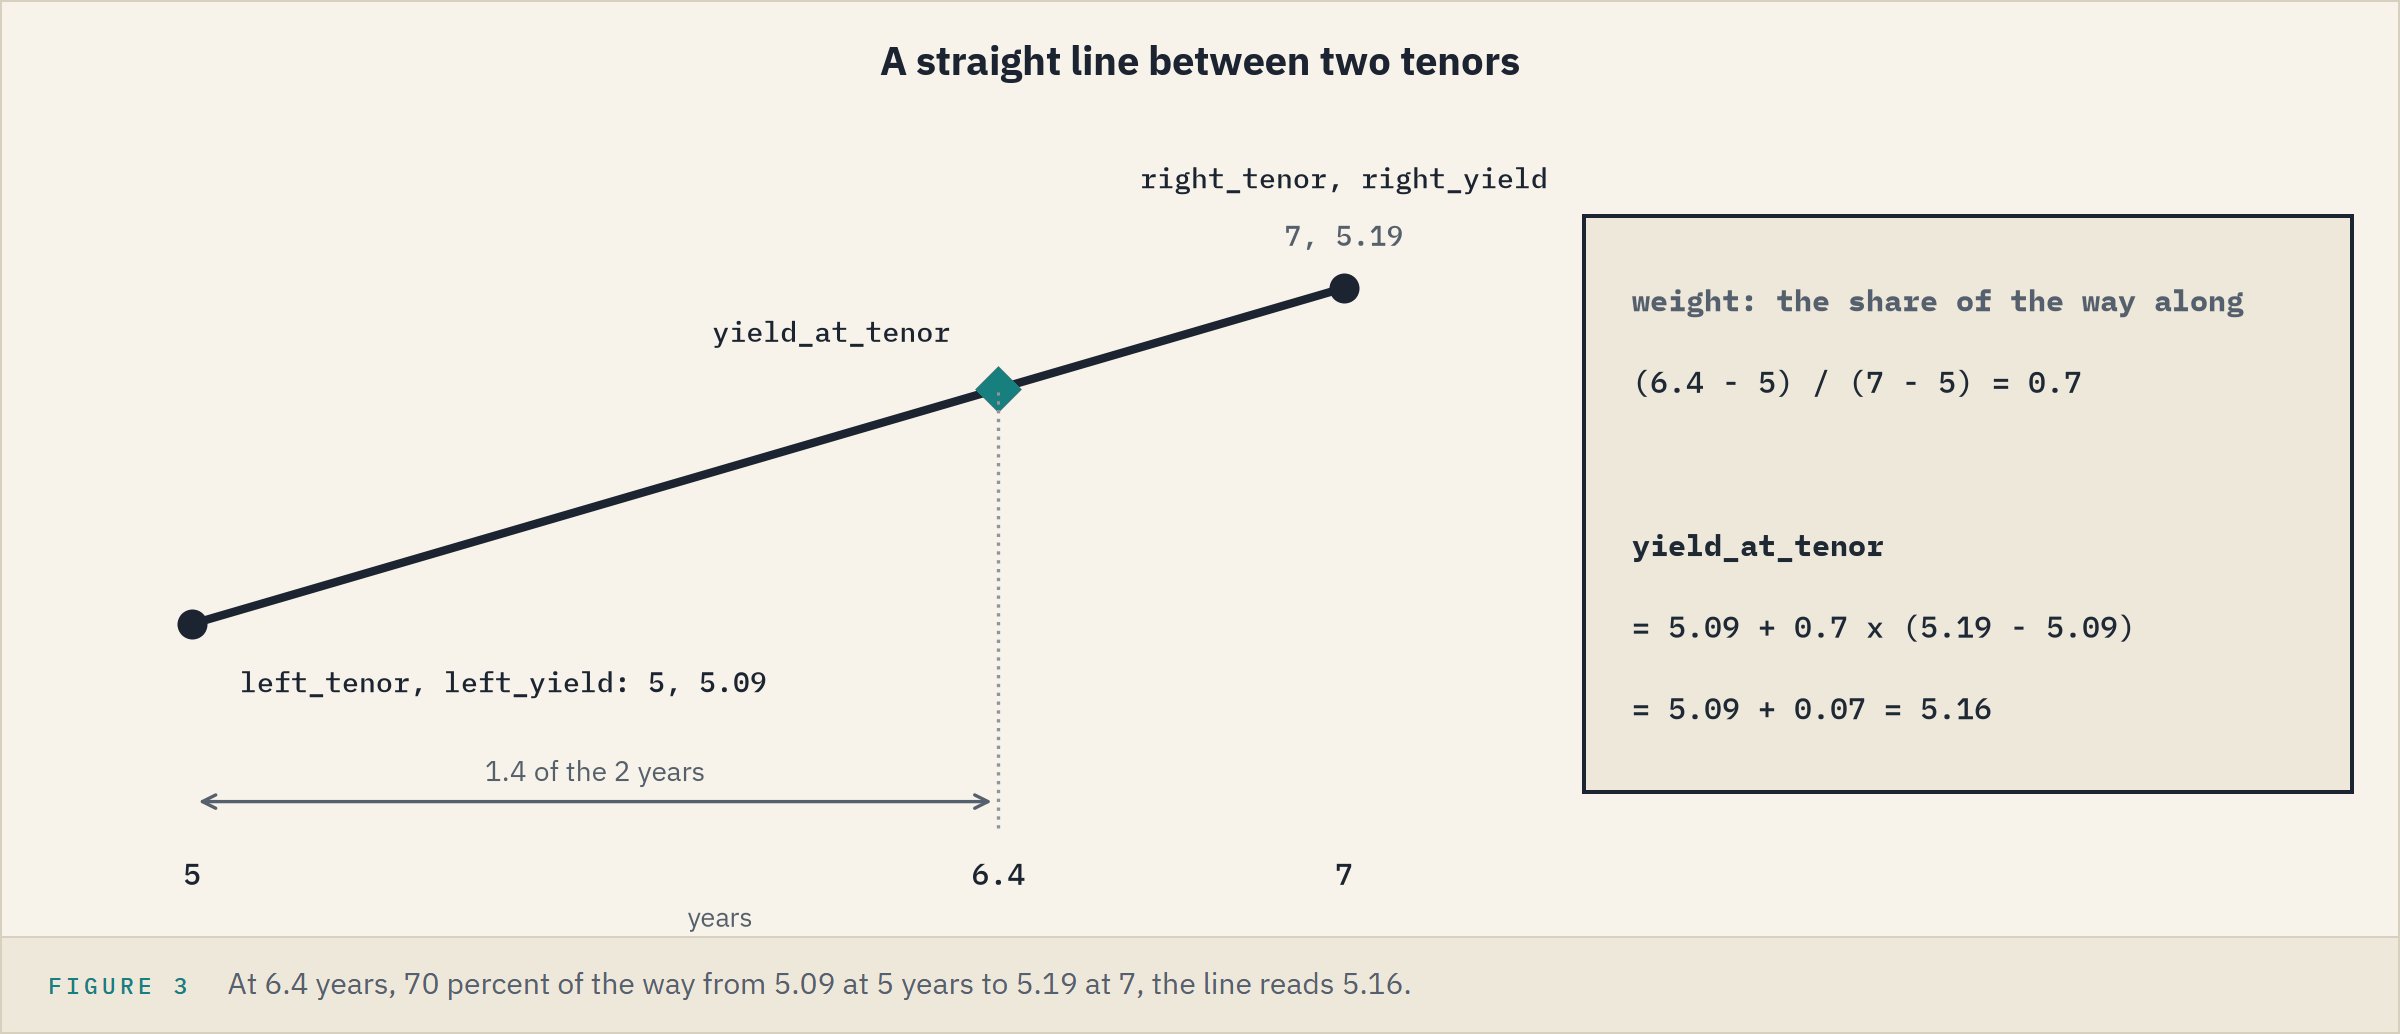

1.4 of the 2 years along is a weight of 0.7, and 0.7 of the 0.10 rise from 5.09 is 0.07.
The answer is a weighted average of the two neighbours, with more weight on the nearer one.

### Zoom In on the Line

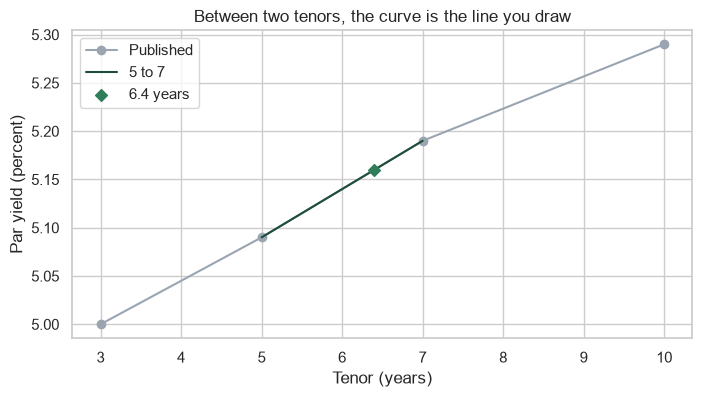

In [8]:
# the published points from 3 to 10 years, the line used, and the point read off it
window = real_curve[real_curve['tenor_years'].between(3, 10)]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(window['tenor_years'], window['yield_pct'], marker='o', color='#9AA5B1', label='Published')
ax.plot([left_tenor, right_tenor], [left_yield, right_yield], color='#1E4D3A', label='5 to 7')
ax.scatter(6.4, yield_at_tenor, marker='D', color='#2E7D5B', label='6.4 years', zorder=3)
ax.set_title('Between two tenors, the curve is the line you draw')
ax.set_xlabel('Tenor (years)')
ax.set_ylabel('Par yield (percent)')
ax.legend(loc='upper left')
plt.show()

The dark line is the only part of the curve the answer uses: a choice of method, not a published figure.

**Excel side by side.** 5 and 7 in A2:A3, 5.09 and 5.19 in B2:B3.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">The line written out</td><td align="left"><code>left_yield + weight * (right_yield - left_yield)</code></td><td align="left"><code>=B2+(B3-B2)*(6.4-A2)/(A3-A2)</code></td><td align="left">5.16</td></tr>
<tr><td align="left">The line by Excel</td><td align="left"><code>yield_at_tenor</code></td><td align="left"><code>=FORECAST.LINEAR(6.4,B2:B3,A2:A3)</code></td><td align="left">5.160000000000001</td></tr>
<tr><td align="left">Arguments swapped</td><td align="left">(none)</td><td align="left"><code>=FORECAST.LINEAR(6.4,A2:A3,B2:B3)</code></td><td align="left">31.19999999999986, no error</td></tr>
</table>
<br clear="left">

`FORECAST.LINEAR` takes the yields before the tenors; swapped, it forecasts a tenor and says nothing.
Yields in percent go in and come out: a straight line needs no `/100`.

### Find the Bracket

Q. For 200 bonds the code must find the bracket itself. Which two tenors are around 6.4 years?

In [9]:
tenors = real_curve['tenor_years'].tolist()
labels = real_curve['label'].tolist()
# step right while the tenor is still short of 6.4 years
i = 0
while tenors[i] < 6.4:
    i += 1
print(f'6.4 years lies between {labels[i - 1]} and {labels[i]}: positions {i - 1} and {i}')

6.4 years lies between 5 Yr and 7 Yr: positions 9 and 10


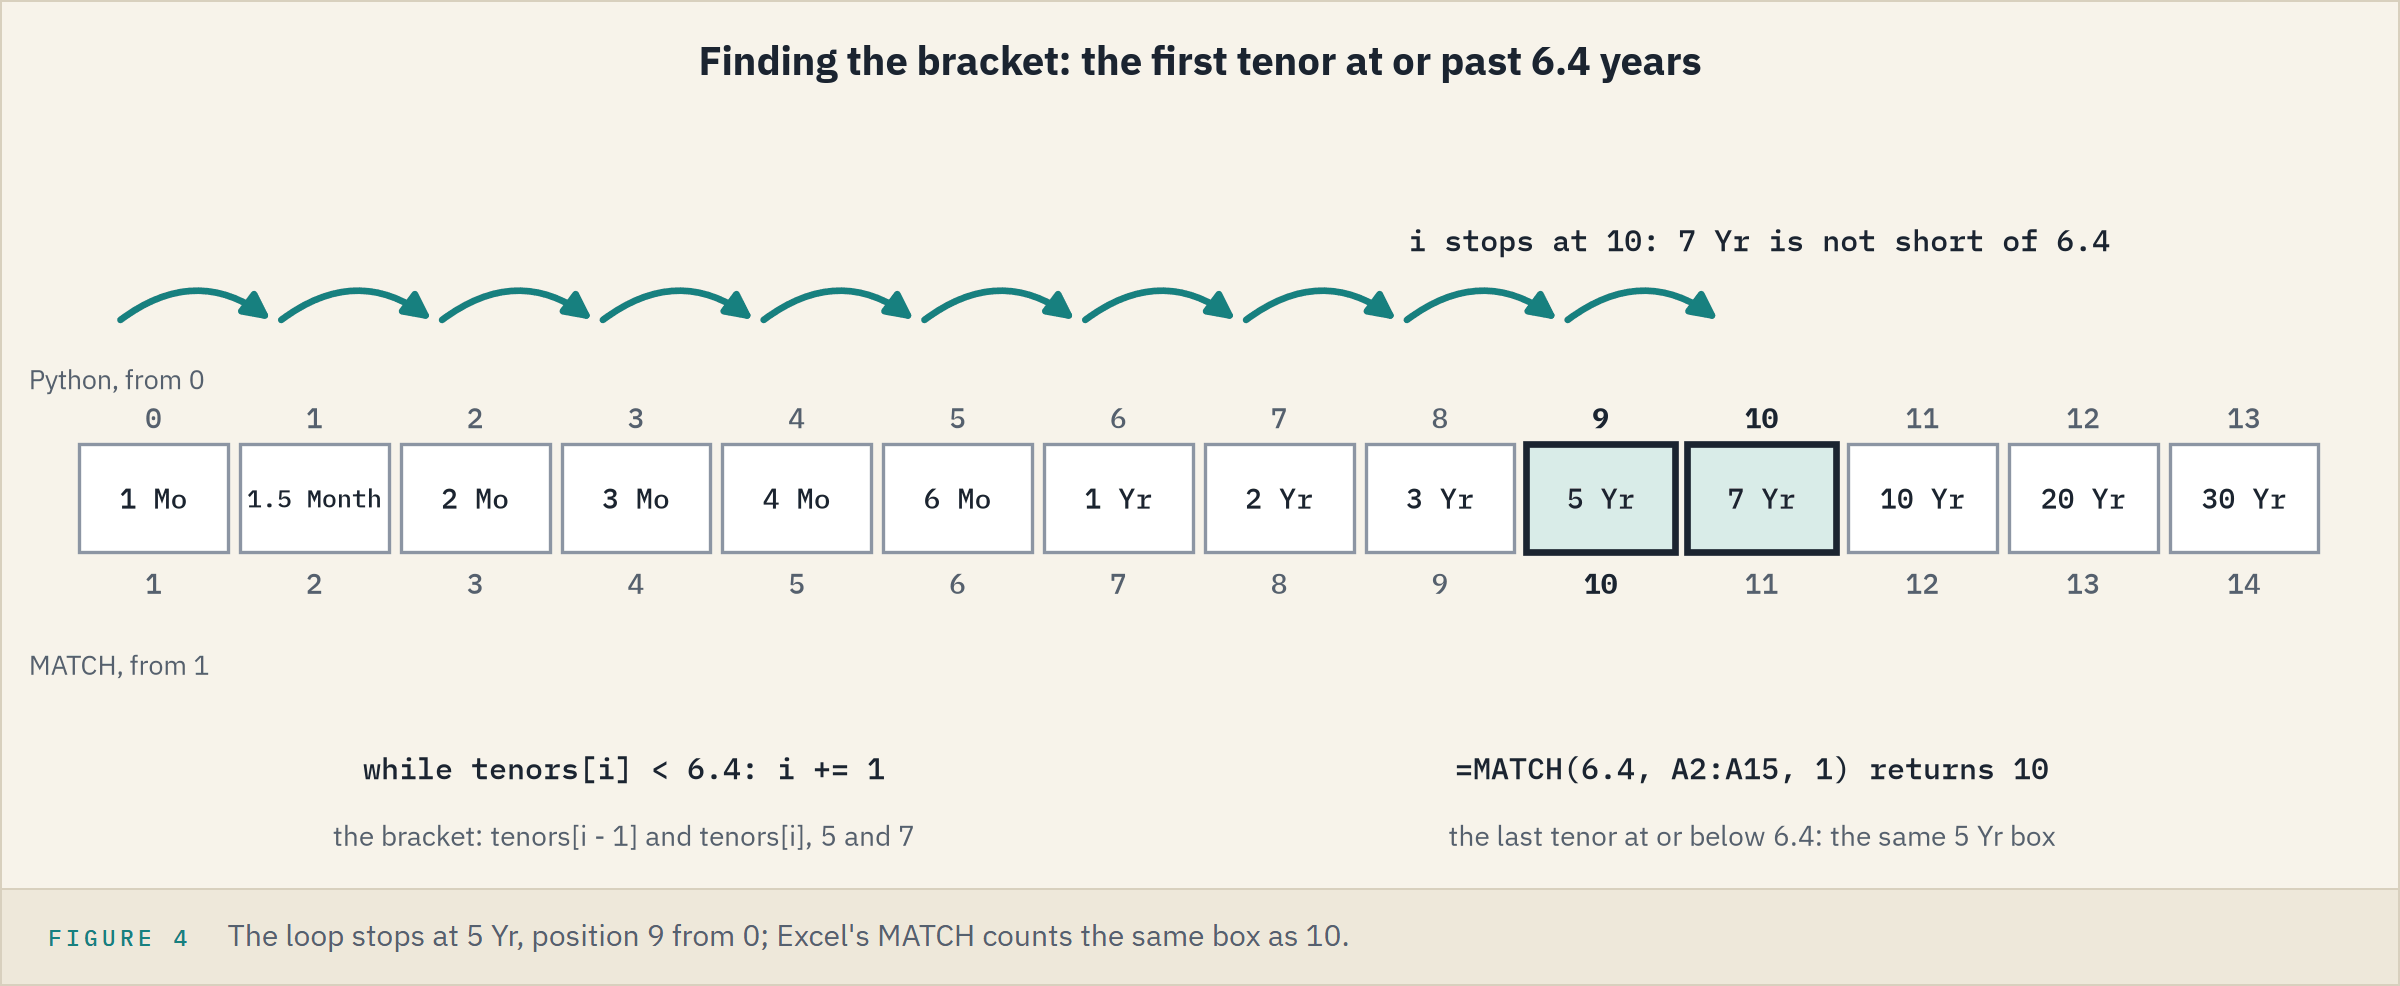

Python counts positions from 0, so `5 Yr` is position 9; Excel's `MATCH` counts from 1 and calls it 10.

**Excel side by side.** The fourteen tenors in A2:A15, 6.4 in D1.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">The bracket's position</td><td align="left">the <code>while</code> loop</td><td align="left"><code>=MATCH(D1,A2:A15,1)</code></td><td align="left">10, counted from 1</td></tr>
<tr><td align="left">The bracket's tenors</td><td align="left"><code>tenors[i - 1]</code>, <code>tenors[i]</code></td><td align="left"><code>=INDEX(A2:A15,MATCH(D1,A2:A15,1))</code>, and with <code>+1</code> after the <code>MATCH</code></td><td align="left">5 and 7</td></tr>
</table>
<br clear="left">

**5.16 percent by hand, the same line as Excel's `FORECAST.LINEAR`, and a loop that finds the bracket for any maturity.**

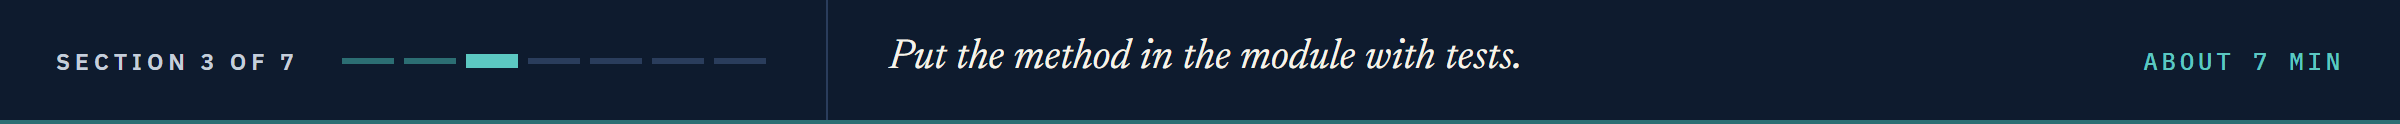

## 11.3 `interpolate_yield`, Docstring First

Three decisions go into the docstring before any code:

* **Units:** tenors in years, yields in percent, the result in percent.
* **Flat ends** (**flat extrapolation**): below the first tenor, the first yield; past the last, the last yield, so no slope is invented beyond the curve.
* **The check:** the tenors must ascend, or the bracket search reads the wrong pair, so a jumbled curve raises `ValueError`.

### Append It

In [10]:
%%writefile -a bondmath.py


def interpolate_yield(tenor_years: float, curve_tenors: list[float], curve_yields_pct: list[float]) -> float:
    """Yield at any tenor by straight-line interpolation on a curve, flat beyond its ends.

    Units: tenors in years, yields in percent; the result is in percent.
    Convention: linear in yield against tenor between the two curve points around tenor_years. Below
    the first tenor the first yield is used, above the last tenor the last yield (as numpy.interp).
    Raises ValueError if the lists differ in length, are empty, or the tenors do not ascend.
    """
    # stop on a curve the function cannot read
    if len(curve_tenors) != len(curve_yields_pct) or len(curve_tenors) == 0:
        raise ValueError("curve_tenors and curve_yields_pct must be non-empty and the same length")
    for i in range(1, len(curve_tenors)):
        if curve_tenors[i] <= curve_tenors[i - 1]:
            raise ValueError(f"curve tenors must ascend: {curve_tenors[i - 1]} then {curve_tenors[i]}")
    # flat beyond the ends
    if tenor_years <= curve_tenors[0]:
        return curve_yields_pct[0]
    if tenor_years >= curve_tenors[-1]:
        return curve_yields_pct[-1]
    # find the two tenors around tenor_years
    i = 1
    while curve_tenors[i] < tenor_years:
        i += 1
    left_tenor, right_tenor = curve_tenors[i - 1], curve_tenors[i]
    left_yield, right_yield = curve_yields_pct[i - 1], curve_yields_pct[i]
    # move along the straight line between them
    slope = (right_yield - left_yield) / (right_tenor - left_tenor)
    return left_yield + slope * (tenor_years - left_tenor)

Appending to bondmath.py


The checks, the flat ends, 11.2's bracket loop, then 11.2's line written as a slope: the rise per year times the years along.

### The Hand Answer, Exactly

In [11]:
importlib.reload(bondmath)
real_tenors = real_curve['tenor_years'].tolist()
real_yields = real_curve['yield_pct'].tolist()
from_module = bondmath.interpolate_yield(6.4, real_tenors, real_yields)
# the module must give exactly the hand answer
assert from_module == yield_at_tenor
print(f'interpolate_yield at 6.4 years: {from_module:.4f} percent')

interpolate_yield at 6.4 years: 5.1600 percent


### On a Tenor, Below, Beyond

In [12]:
# a published tenor, about a week, and past the last tenor
for tenor in [10, 0.02, 40]:
    result = bondmath.interpolate_yield(tenor, real_tenors, real_yields)
    print(f'{tenor:>5} years: {result:.2f} percent')

   10 years: 5.29 percent
 0.02 years: 4.02 percent
   40 years: 5.64 percent


On the 10-year tenor, the published 5.29; at 0.02 years, the `1 Mo` yield; at 40 years, the `30 Yr`.

### Straight Between, Flat Beyond

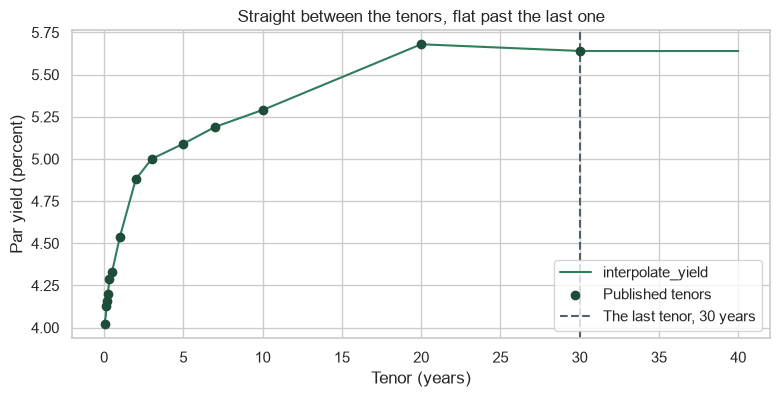

In [13]:
# 401 tenors from 0 to 40 years, made with Course 1's np.linspace
fine_tenors = np.linspace(0, 40, 401)
returned = [bondmath.interpolate_yield(t, real_tenors, real_yields) for t in fine_tenors]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(fine_tenors, returned, label='interpolate_yield')
ax.scatter(real_tenors, real_yields, color='#1E4D3A', label='Published tenors', zorder=3)
ax.axvline(30, color='#52606D', linestyle='--', label='The last tenor, 30 years')
ax.set_title('Straight between the tenors, flat past the last one')
ax.set_xlabel('Tenor (years)')
ax.set_ylabel('Par yield (percent)')
ax.legend(loc='lower right')
plt.show()

### A Jumbled Curve

Q. What does it do with a curve typed with 3 years before 2?

In [14]:
bondmath.interpolate_yield(4, [1, 3, 2], [3.7, 3.9, 3.8])

ValueError: curve tenors must ascend: 3 then 2

It refuses, and says where.

### The Tests

Four tests, on the invented curve of The Data, typed as `CURVE_TENORS` and `CURVE_YIELDS_PCT`:

* `test_on_a_tenor_returns_its_yield`: each of the ten points gives back its own yield.
* `test_matches_numpy_interp`: nine tenors, inside and outside, agree to 1e-12 with numpy's own straight line, `np.interp` (11.4), imported inside the test because `bondmath` does not use numpy.
* `test_flat_beyond_the_ends` and `test_raises_when_tenors_not_ascending`: two of the docstring's decisions.

In [15]:
%%writefile -a test_bondmath.py


# The invented curve the holdings file was built on, at ten tenors: round(3.55 + 1.05 x (1 - exp(-T / 7)), 3)
CURVE_TENORS = [0.25, 0.5, 1, 2, 3, 5, 7, 10, 20, 30]
CURVE_YIELDS_PCT = [3.587, 3.622, 3.69, 3.811, 3.916, 4.086, 4.214, 4.348, 4.54, 4.586]


def test_on_a_tenor_returns_its_yield():
    for tenor, yield_pct in zip(CURVE_TENORS, CURVE_YIELDS_PCT):
        assert bondmath.interpolate_yield(tenor, CURVE_TENORS, CURVE_YIELDS_PCT) == pytest.approx(yield_pct, abs=1e-12)


def test_matches_numpy_interp():
    import numpy as np  # numpy is in the course requirements; bondmath itself does not use it

    for tenor in (0.1, 0.92, 1.5, 4.0, 6.4, 8.75, 15.0, 29.9, 35.0):
        expected = float(np.interp(tenor, CURVE_TENORS, CURVE_YIELDS_PCT))
        assert bondmath.interpolate_yield(tenor, CURVE_TENORS, CURVE_YIELDS_PCT) == pytest.approx(expected, abs=1e-12)


def test_flat_beyond_the_ends():
    # below the first tenor: the first yield; above the last: the last yield
    assert bondmath.interpolate_yield(0.1, CURVE_TENORS, CURVE_YIELDS_PCT) == 3.587
    assert bondmath.interpolate_yield(40, CURVE_TENORS, CURVE_YIELDS_PCT) == 4.586


def test_raises_when_tenors_not_ascending():
    with pytest.raises(ValueError):
        bondmath.interpolate_yield(4, [1, 3, 2], [3.7, 3.9, 3.8])

Appending to test_bondmath.py


### Run Them

In [16]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

................................                                         [100%]
32 passed in 0.50s



### Excel's Answers

Excel reads a whole curve with one formula: `MATCH` finds the row, and `INDEX` hands two points to `FORECAST.LINEAR`.

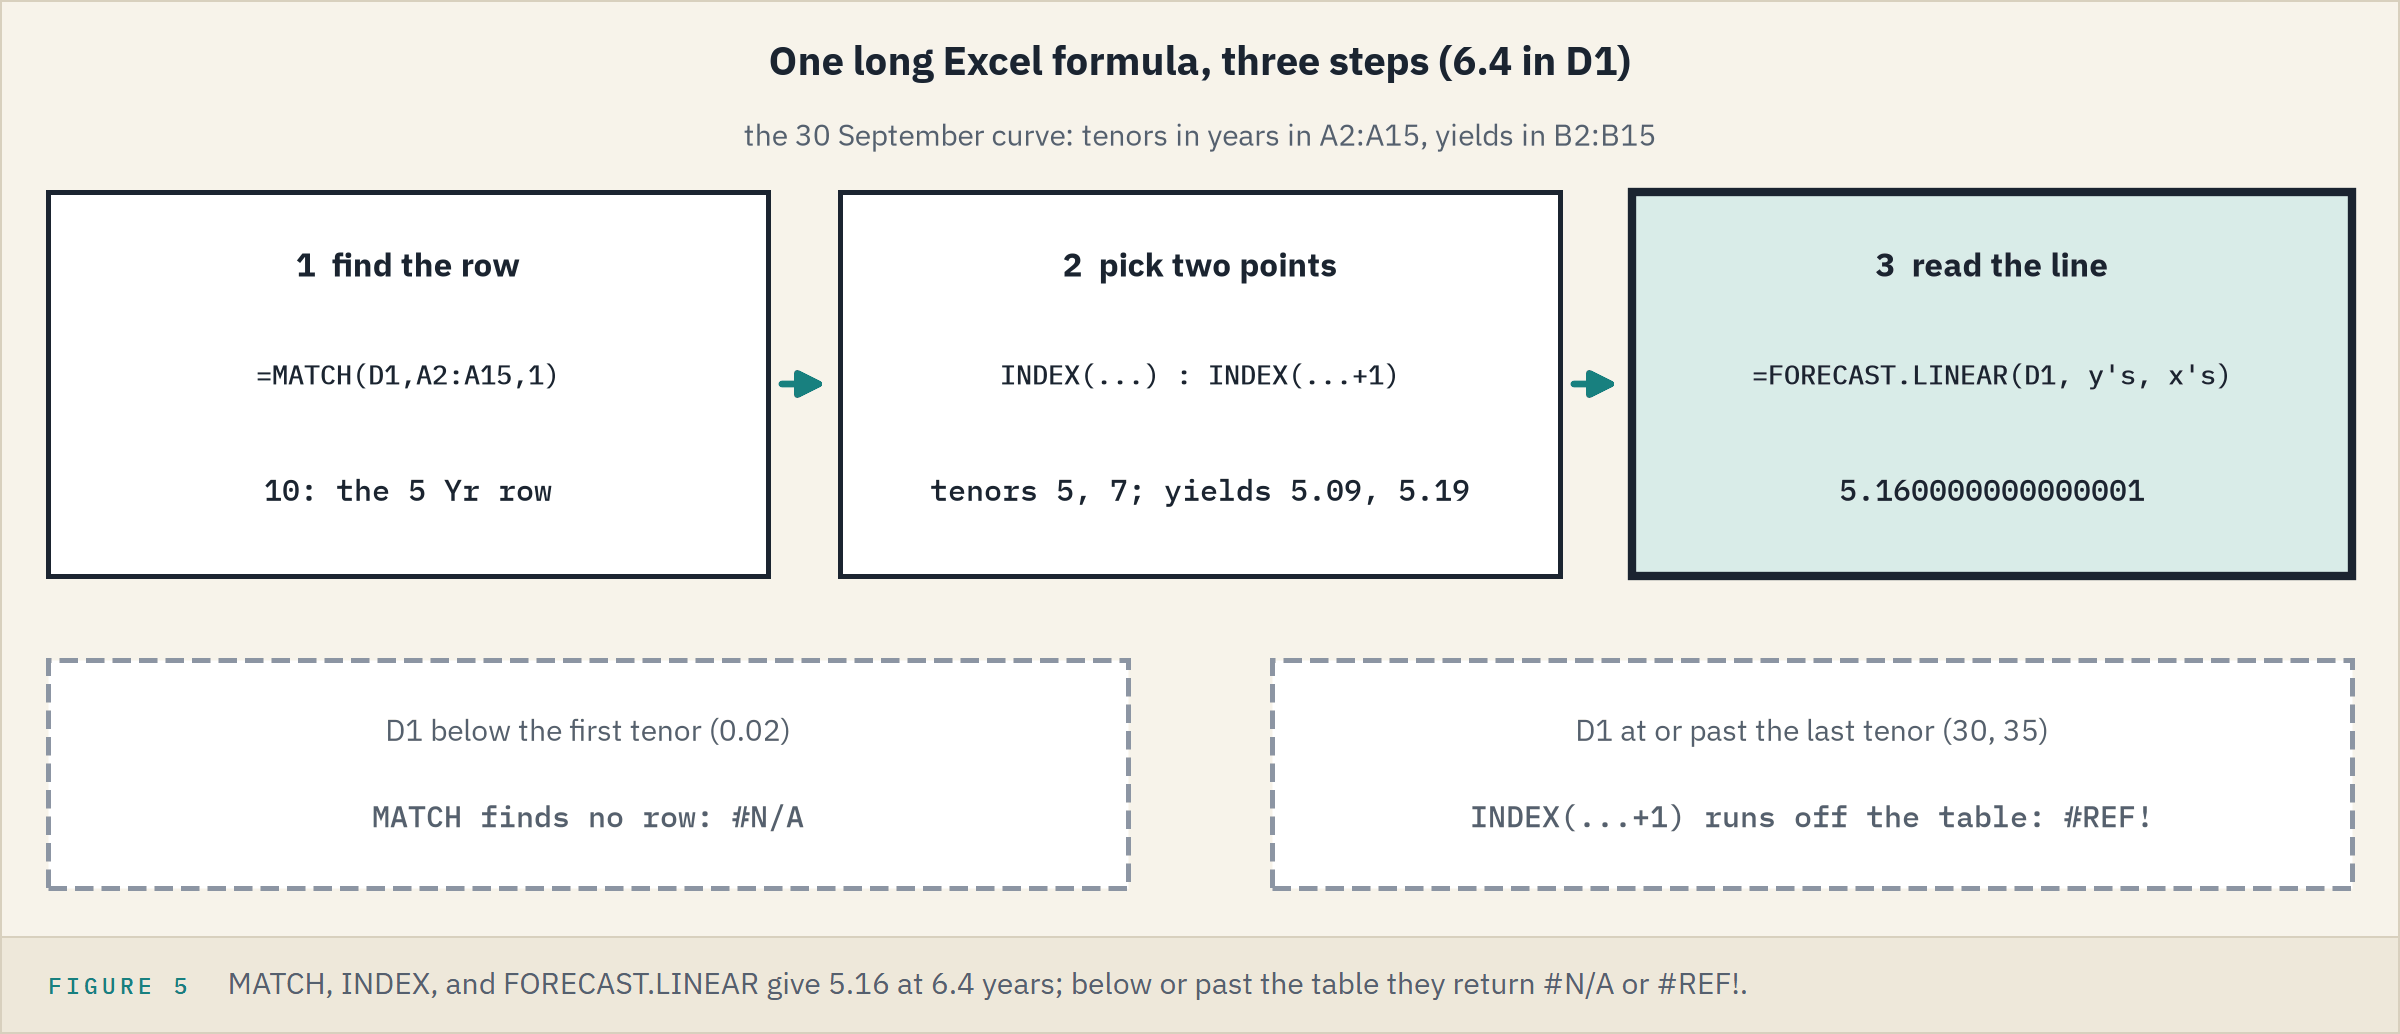

**Excel side by side.** The curve in A2:B15, the tenor to read in D1.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Any tenor inside</td><td align="left"><code>bondmath.interpolate_yield(6.4, real_tenors, real_yields)</code></td><td align="left"><code>=FORECAST.LINEAR(D1,INDEX(B2:B15,MATCH(D1,A2:A15,1)):INDEX(B2:B15,MATCH(D1,A2:A15,1)+1),INDEX(A2:A15,MATCH(D1,A2:A15,1)):INDEX(A2:A15,MATCH(D1,A2:A15,1)+1))</code></td><td align="left">5.160000000000001</td></tr>
<tr><td align="left">Below the first tenor</td><td align="left">flat: 4.02 at 0.02</td><td align="left">the same</td><td align="left"><code>#N/A</code></td></tr>
<tr><td align="left">At or past the last</td><td align="left">5.64 at 30, and flat at 35</td><td align="left">the same</td><td align="left"><code>#REF!</code></td></tr>
</table>
<br clear="left">

Use the formula strictly inside the curve; the flat ends are the function's job.

Q. Does `interpolate_yield` return what Excel's formula returned, on both curves?

In [17]:
from test_bondmath import CURVE_TENORS, CURVE_YIELDS_PCT
# Excel's formula on each curve: tenor in years, yield in percent
excel_real = {6.4: 5.160000000000001, 0.5: 4.330000000000001, 2.5: 4.9399999999999995,
              8.5: 5.24, 15: 5.484999999999999, 25: 5.66, 10: 5.29}
excel_invented = {0.25: 3.587, 0.92: 3.6791199999999993, 6.4: 4.1756, 10: 4.348,
                  15: 4.444, 29.5: 4.583700000000001}
gaps = [bondmath.interpolate_yield(t, real_tenors, real_yields) - y
        for t, y in excel_real.items()]
gaps += [bondmath.interpolate_yield(t, CURVE_TENORS, CURVE_YIELDS_PCT) - y
         for t, y in excel_invented.items()]
print(f'{len(gaps)} tenors; largest gap from Excel: {max([abs(g) for g in gaps]):.1e} percent')

13 tenors; largest gap from Excel: 8.9e-16 percent


A gap of 8.9e-16 percent is the last binary digit: Excel and Python draw the same line.

**Excel's answers inside the curve, flat outside it, a refusal for a jumbled curve: 32 tests pass.**

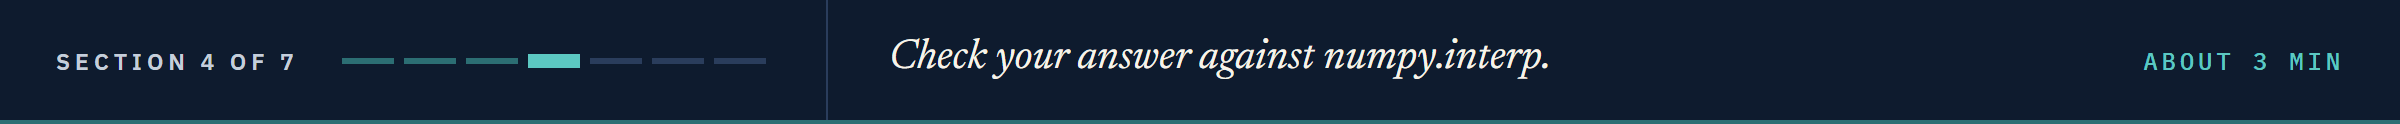

## 11.4 The Same With `numpy.interp`

numpy has the straight line built in: `np.interp(x, tenors, yields)`, for one tenor or a list of them.

### Eight Tenors, Two Answers

In [18]:
eight_tenors = [0.02, 0.5, 2.5, 6.4, 8.5, 15, 25, 40]
comparison = pd.DataFrame({'tenor_years': eight_tenors})
comparison['ours'] = [bondmath.interpolate_yield(t, real_tenors, real_yields)
                      for t in eight_tenors]
comparison['numpy'] = np.interp(eight_tenors, real_tenors, real_yields)
comparison['difference'] = comparison['ours'] - comparison['numpy']
comparison

,tenor_years,ours,numpy,difference
0,0.02,4.020,4.020,0.0
1,0.50,4.330,4.330,0.0
2,2.50,4.940,4.940,0.0
3,6.40,5.160,5.160,0.0
4,8.50,5.240,5.240,0.0
5,15.00,5.485,5.485,0.0
6,25.00,5.660,5.660,0.0
7,40.00,5.640,5.640,0.0


Every tenor agrees, both flat ends included.

**Predict 2**

Q. 11.3's jumbled curve stopped `interpolate_yield`. Hand it to numpy and ask for 4 years: `np.interp(4, [1, 3, 2], [3.7, 3.9, 3.8])`.

A) it raises a `ValueError`, as `interpolate_yield` did
B) it sorts the tenors first and returns 3.9
C) it keeps the list as typed and returns its last yield

### Ask NumPy

In [19]:
print(np.interp(4, [1, 3, 2], [3.7, 3.9, 3.8]))

3.8


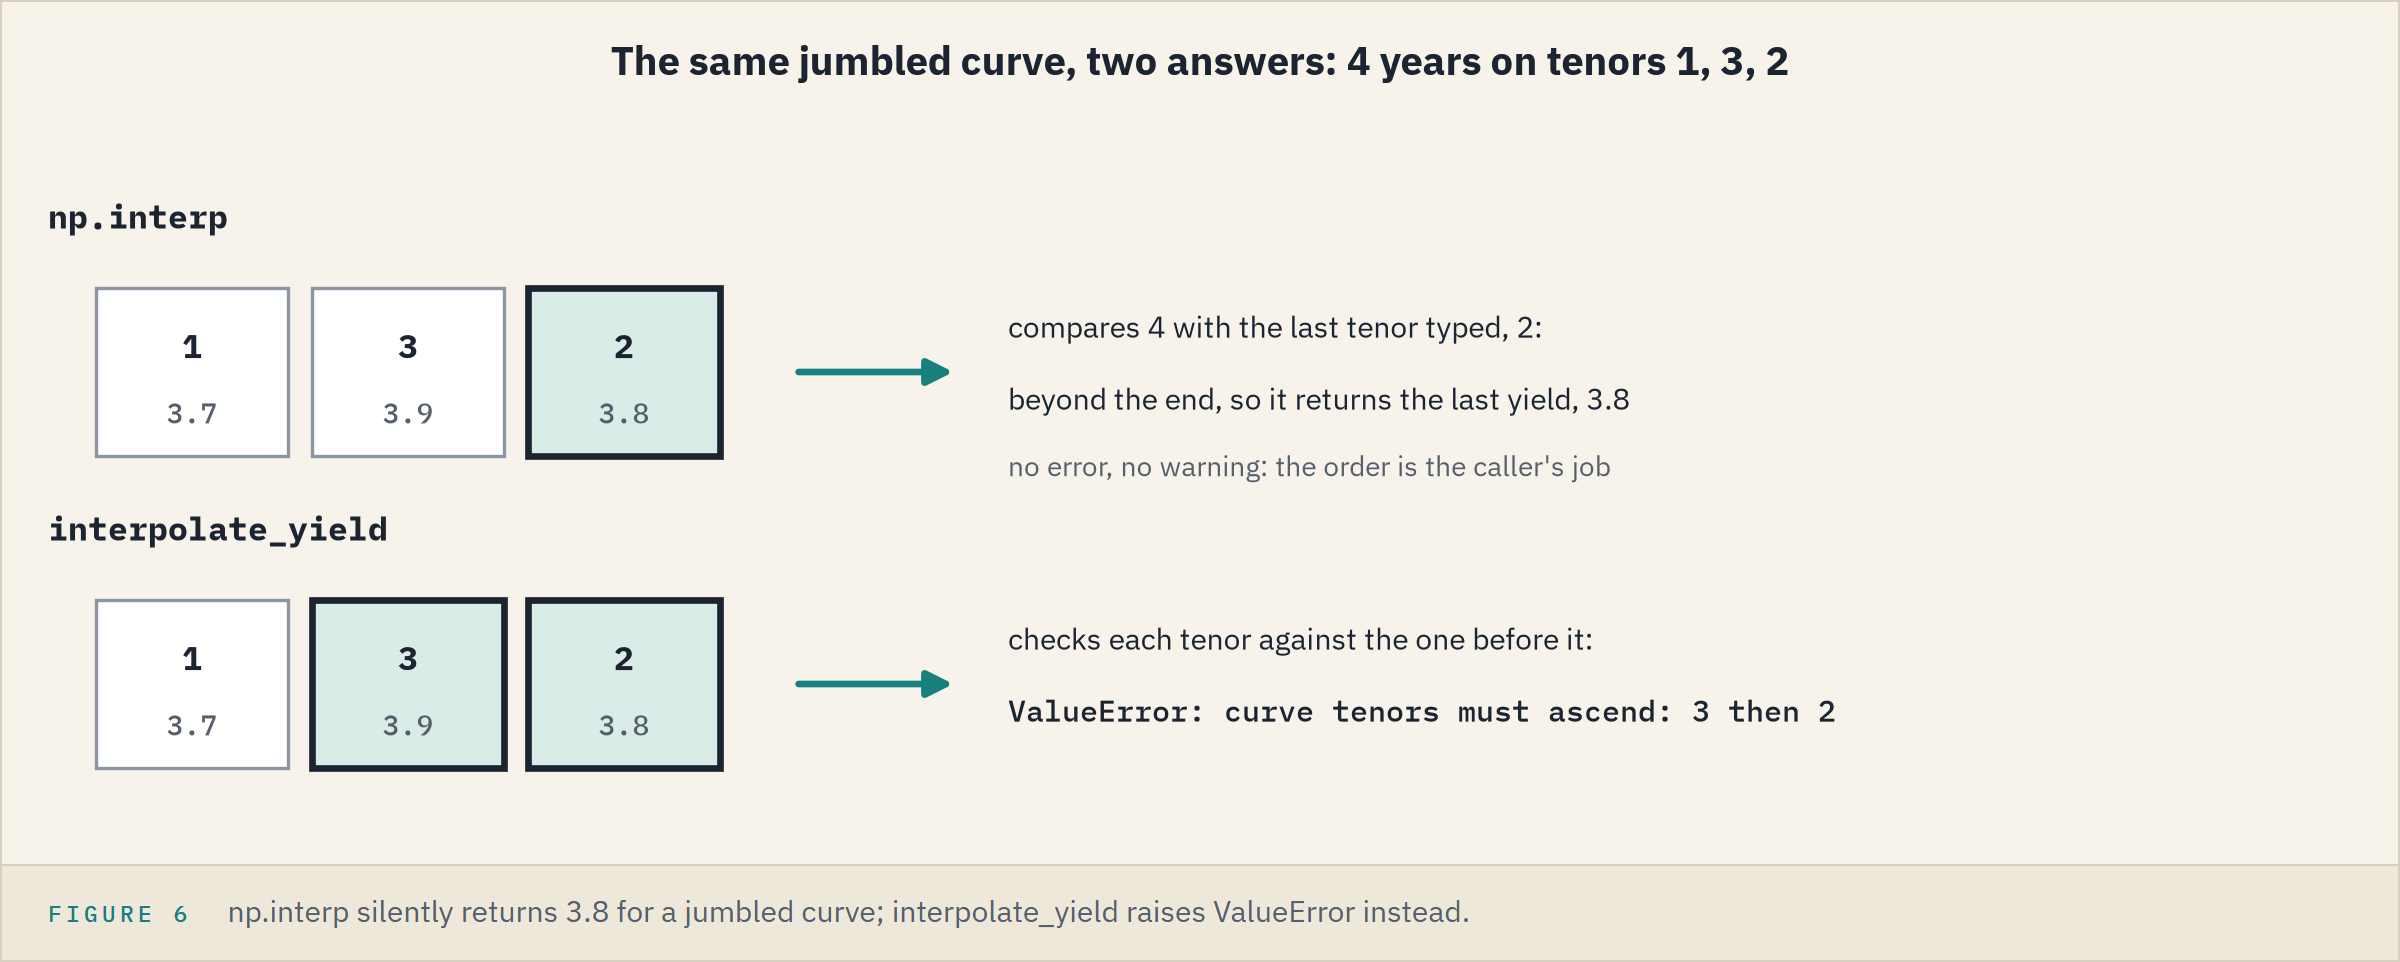

C: 3.8, with no error and no warning.
numpy's own page says the tenors are expected to increase, that this is not enforced, and that otherwise the results are meaningless ([numpy.interp](https://numpy.org/doc/stable/reference/generated/numpy.interp.html), numpy 2.5.3).

**numpy agrees everywhere and checks nothing: the order is the caller's job, and `interpolate_yield` does it.**

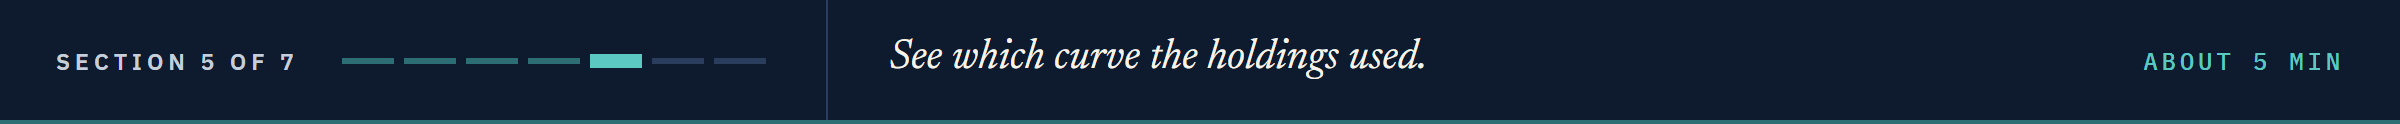

## 11.5 The Curve the Holdings Were Built On

The holdings file's yields were built on the invented curve, not on Treasury's; the repo's `DATA.md` gives its formula:

yield in percent = 3.55 + 1.05 x (1 - exp(-T / 7)), with T the years to maturity.

It starts at 3.55, levels off toward 3.55 + 1.05 = 4.60, and 7 sets how fast; `exp` is Course 1's `np.exp`.
At T = 7, exp(-1) is 0.3679, so the yield is 3.55 + 1.05 x 0.6321 = 4.2137 percent, 4.214 to 3 decimals.
The program that wrote the file added each bond's spread to it.

### Read It, Check It

In [20]:
invented = pd.read_csv('course2_treasury_curve.csv')
invented_tenors = invented['tenor_years'].tolist()
invented_yields = invented['yield_pct'].tolist()
# the formula at each tenor, rounded to 3 decimals as the file was
formula_pct = np.round(3.55 + 1.05 * (1 - np.exp(-invented['tenor_years'] / 7)), 3)
assert (formula_pct == invented['yield_pct']).all()
invented

,tenor_years,yield_pct
0,0.25,3.587
1,0.50,3.622
2,1.00,3.690
3,2.00,3.811
4,3.00,3.916
5,5.00,4.086
6,7.00,4.214
7,10.00,4.348
8,20.00,4.540
9,30.00,4.586


Each point is the formula rounded to 3 decimals; notebook 12 meets that rounding again.
The table starts at 0.25 years because Course 1's October book holds a bond with 0.92 years left; the holdings run from 1.01 to 29.90 years, all inside it.

**Excel side by side.** With the ten points in A2:B11 and the formula's ranges ending at row 11, Excel returns 4.1756 at 6.4 years, `#N/A` at 0.1 and `#REF!` at 30, as on the real curve.

### Two Curves on One Axis

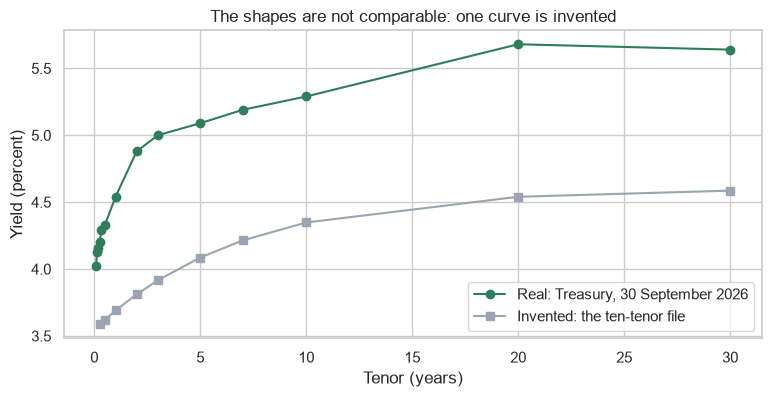

In [21]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(real_tenors, real_yields, marker='o', label='Real: Treasury, 30 September 2026')
ax.plot(invented_tenors, invented_yields, marker='s', label='Invented: the ten-tenor file')
ax.set_title('The shapes are not comparable: one curve is invented')
ax.set_xlabel('Tenor (years)')
ax.set_ylabel('Yield (percent)')
ax.legend(loc='lower right')
plt.show()

**The shapes are not comparable, because one curve is invented**: it was written to give synthetic bonds believable yields, never fitted to Treasury's figures.

### The Tests' Ten Points Are the File's

Q. Do the tests type exactly the file's points?

In [22]:
# CURVE_TENORS and CURVE_YIELDS_PCT came from the test file in 11.3
assert CURVE_TENORS == invented_tenors
assert CURVE_YIELDS_PCT == invented_yields
print(len(CURVE_TENORS), 'points: the tests type exactly the file')

10 points: the tests type exactly the file


### What Git Sees, and What It Leaves Out

Q. What changed in the work folder today, and what does Git leave out?

In [23]:
# --ignored: also list the files Git leaves out, marked !!
!git -C "{work}" status --short --ignored
!git -C "{work}" diff --stat

 M bondmath.py
 M test_bondmath.py
!! __pycache__/
!! bondmath_excel_reference.csv
!! bondmath_excel_reference_tvm.csv
!! course2_treasury_curve.csv
!! treasury_par_yields.csv
 bondmath.py      | 30 ++++++++++++++++++++++++++++++
 test_bondmath.py | 29 +++++++++++++++++++++++++++++
 2 files changed, 59 insertions(+)


`!!` marks what Git leaves out: `__pycache__` by notebook 06's `.gitignore`, the data files because `start_day` lists them in Git's own ignore list.
The curve file is data: it comes from its source, the repo's data folder, not from the module's record.

### Commit the Module and Its Tests

In [24]:
!git -C "{work}" add bondmath.py test_bondmath.py
subject = 'Add interpolate_yield: linear between tenors, flat beyond the ends'
body = 'Week 3 reads a curve yield at each maturity; the tests hold it to numpy.interp.'
!git -C "{work}" commit -q -m "{subject}" -m "{body}"
!git -C "{work}" log --oneline -1

fa6939c Add interpolate_yield: linear between tenors, flat beyond the ends


**Every Course 2 spread is measured from this curve: the tests type its ten points, and the history holds the module and its tests, never the data.**

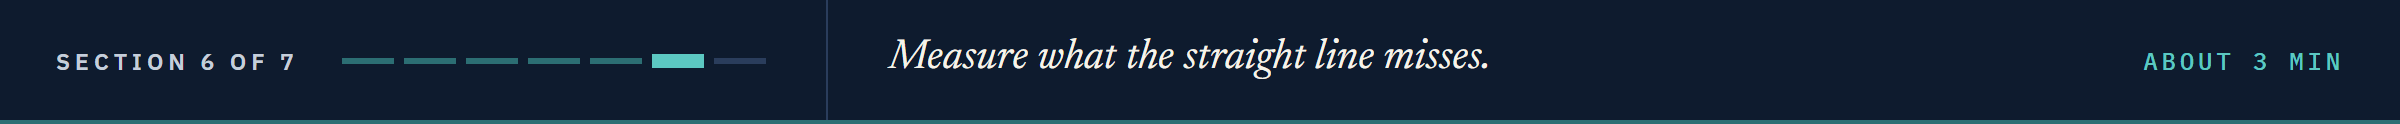

## 11.6 How Far the Straight Line Sits From the Smooth Curve

Between its ten points the invented curve bends; `interpolate_yield` draws straight lines.

**Predict 3**

Q. Read the invented curve every 0.01 years, from the formula and from the straight lines through its ten points. Where are the two furthest apart?

A) under 1 year, where the curve rises fastest
B) between 10 and 20 years
C) between 20 and 30 years, the last stretch

### Every 0.01 Years

In [25]:
# 2,976 tenors, 0.01 years apart, from 0.25 to 30 years
grid = np.linspace(0.25, 30, 2976)
from_formula = 3.55 + 1.05 * (1 - np.exp(-grid / 7))
from_lines = np.array([bondmath.interpolate_yield(t, invented_tenors, invented_yields)
                       for t in grid])
# the formula minus the line, in bp: 1 percent is 100 bp
gap_bp = (from_formula - from_lines) * 100
print(f'largest gap: {gap_bp.max():.2f} bp, at {grid[gap_bp.argmax()]:.2f} years')
print(f'average gap: {gap_bp.mean():.2f} bp')

largest gap: 3.33 bp, at 14.39 years
average gap: 1.01 bp


B: 3.33 bp at 14.39 years, and 1.01 bp on average over the grid.
A curve that rises ever more slowly bends above any straight line between two of its points; the wide stretch from 10 to 20 years, where it still bends, leaves the most room.
At the ten tenors the gap is only the file's rounding, under 0.05 bp.

### Smooth Against Straight, 7 to 30 Years

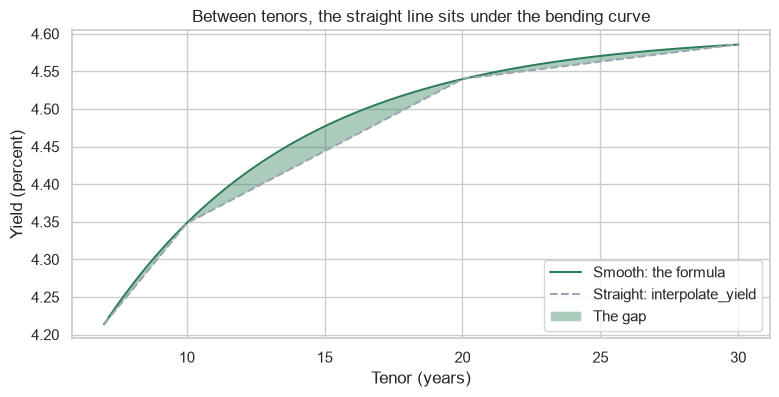

In [26]:
far = grid >= 7
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(grid[far], from_formula[far], label='Smooth: the formula')
ax.plot(grid[far], from_lines[far], linestyle='--', label='Straight: interpolate_yield')
# the area between the two, shaded as in notebook 10
ax.fill_between(grid[far], from_lines[far], from_formula[far], alpha=0.4, label='The gap')
ax.set_title('Between tenors, the straight line sits under the bending curve')
ax.set_xlabel('Tenor (years)')
ax.set_ylabel('Yield (percent)')
ax.legend(loc='lower right')
plt.show()

### The Gap, Tenor by Tenor

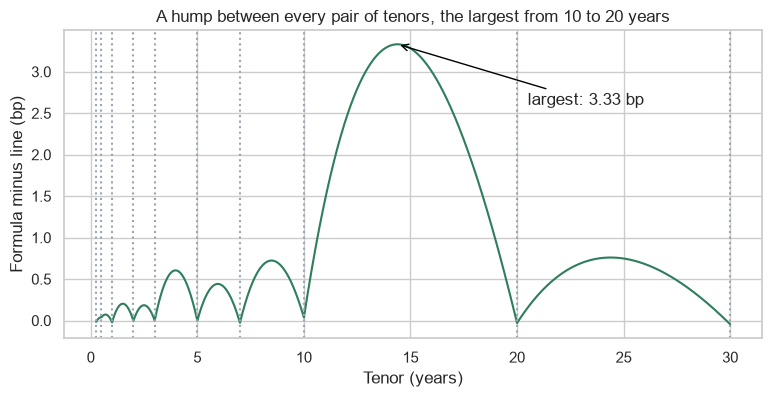

In [27]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(grid, gap_bp)
# a dotted line at each tenor, where the two agree
for tenor in invented_tenors:
    ax.axvline(tenor, color='#9AA5B1', linestyle=':')
ax.annotate(f'largest: {gap_bp.max():.2f} bp', xy=(grid[gap_bp.argmax()], gap_bp.max()),
            xytext=(20.5, 2.6), arrowprops={'arrowstyle': '->', 'color': 'black'})
ax.set_title('A hump between every pair of tenors, the largest from 10 to 20 years')
ax.set_xlabel('Tenor (years)')
ax.set_ylabel('Formula minus line (bp)')
plt.show()

Each hump grows with the room between tenors and with the bend there: 0.04 bp from 0.25 to 0.5 years, 0.72 from 7 to 10, 3.33 from 10 to 20, and only 0.76 from 20 to 30, where the curve has nearly levelled off.

**The interpolation choice moves the number, by up to 3.33 bp on this curve; notebook 12 meets it bond by bond.**

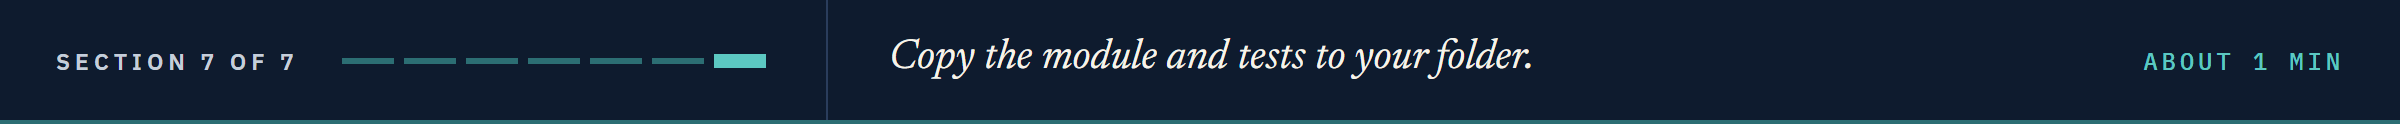

## Bring It Home

Copy the work folder's two files into your `my_bondmath` folder; the copy replaces yours, so anything of your own must be in the work folder first.
In PowerShell in VS Code, with the course's `.venv` active and the folder name the setup printed:

```powershell
Set-Location "$HOME\projects\my_bondmath"
Copy-Item "$env:TEMP\pfi_course2_11_k4w7q2xr\bondmath.py", "$env:TEMP\pfi_course2_11_k4w7q2xr\test_bondmath.py" .
python -m pytest -q
git diff --stat
git commit -am "Add interpolate_yield: linear between tenors, flat beyond the ends"
```

pytest shows 32 passed, more with your exercise tests.
In Colab, download the two files from the work folder under `/tmp`.
The work folder stays in your temp folder until the system clears it.

## You Can Now

By the end of this notebook, you can:

* Turn Treasury's tenor labels into years and chart a curve at true distances.
* Read a curve between two tenors by hand, as a weighted average of the neighbours.
* Find the bracket with a loop, and with Excel's `MATCH` and `INDEX`.
* Read any tenor with `interpolate_yield`, tied to Excel's `FORECAST.LINEAR` inside the curve, flat beyond it, refusing a jumbled curve.
* Say what `np.interp` leaves to the caller.
* Put a number on what a straight line between tenors misses.
* See what Git leaves out with `git status --short --ignored`, and commit the module and its tests without the data.

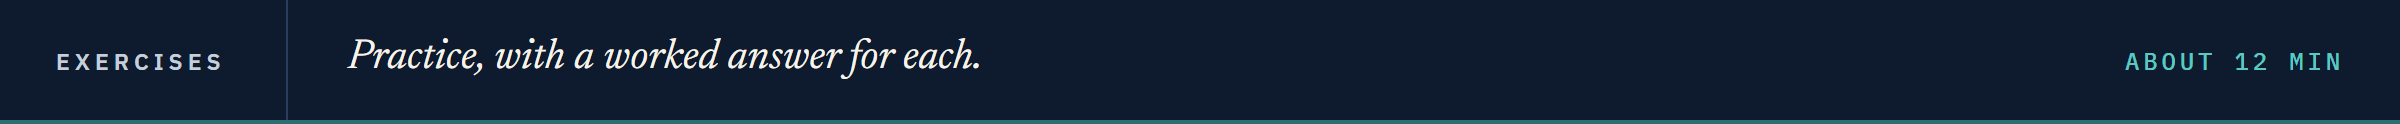

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Replace each `...` with your own code, then run the check cell under it.
Run the next two cells first: `check`, and the curve of 2 October 2026, the file's last date.

In [28]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [29]:
second_row = treasury.loc['2026-10-02']
print(second_row.tolist())

[4.04, 4.09, 4.11, 4.19, 4.26, 4.27, 4.46, 4.83, 4.96, 5.06, 5.17, 5.28, 5.67, 5.63]


### Exercise 1

Q. Interpolate the 2 October curve with `bondmath.interpolate_yield`. Store its yields at 6.4 and 15 years, in percent, in **ex1_6_4** and **ex1_15**, and the change at 6.4 years since 30 September, in bp, in **ex1_change_bp**.

In [30]:
ex1_6_4 = ...
ex1_15 = ...
ex1_change_bp = ...

In [31]:
check('Exercise 1 yield at 6.4 years', ex1_6_4, 5.137)
check('Exercise 1 yield at 15 years', ex1_15, 5.475)
check('Exercise 1 change at 6.4 years in bp', ex1_change_bp, -2.3000000000000576)

Exercise 1 yield at 6.4 years: not attempted yet
Exercise 1 yield at 15 years: not attempted yet
Exercise 1 change at 6.4 years in bp: not attempted yet


### Exercise 2

Q. Course 1's October book holds a bond with 0.92 years left. Read the invented curve there with `interpolate_yield`, in **ex2_line**, and with the formula, unrounded, in **ex2_formula**. Store the formula minus the line, in bp, in **ex2_gap_bp**. Why is it so small?

In [32]:
ex2_line = ...
ex2_formula = ...
ex2_gap_bp = ...

In [33]:
check('Exercise 2 the straight line', ex2_line, 3.67912)
check('Exercise 2 the formula', ex2_formula, 3.679316000311106)
check('Exercise 2 gap in bp', ex2_gap_bp, 0.019600031110567073)

Exercise 2 the straight line: not attempted yet
Exercise 2 the formula: not attempted yet
Exercise 2 gap in bp: not attempted yet


### Exercise 3

Q. Add `tenor_label_to_years(label)` to the module, docstring first (units, the convention, what raises): `'3 Mo'` gives 0.25, `'1.5 Month'` 0.125, `'10 Yr'` 10, and any other unit raises `ValueError`. Add `test_tenor_label_to_years_cases` with `'1 Mo'`, `'1.5 Month'`, `'3 Mo'`, `'30 Yr'`, and a `pytest.raises` case for `'3 Wk'`. Run pytest, reload, and store `bondmath.tenor_label_to_years('3 Mo')` in **ex3_three_months** and how many of the file's 14 labels are under one year in **ex3_under_one_year**.

In [34]:
%%writefile -a bondmath.py


# Exercise 3: write tenor_label_to_years(label) below this line

Appending to bondmath.py


In [35]:
%%writefile -a test_bondmath.py


# Exercise 3: write test_tenor_label_to_years_cases() below this line

Appending to test_bondmath.py


In [36]:
# run pytest as in the lesson, reload the module, then call your function
ex3_three_months = ...
ex3_under_one_year = ...

In [37]:
check('Exercise 3 3 Mo in years', ex3_three_months, 0.25)
check('Exercise 3 labels under one year', ex3_under_one_year, 6)

Exercise 3 3 Mo in years: not attempted yet
Exercise 3 labels under one year: not attempted yet


### Exercise 4: AI check

You asked an assistant for a function that reads a yield straight from a row of the Treasury file, with the docstring below as the prompt.
The function came back, written for this course in the style of an assistant's answer; it runs, and holds one bug.

In [38]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
def assistant_treasury_yield_at(row, tenor_years):
    """Yield in percent at tenor_years on one row of treasury_par_yields.csv, straight between
    the published tenors and flat beyond the ends. Labels such as '3 Mo', '1.5 Month' and
    '10 Yr' become years first: months are twelfths of a year."""
    published = row.dropna()
    tenors, yields = [], []
    for label, yield_pct in zip(published.index, published.values):
        number = float(label.split()[0])
        # Treasury writes some short tenors in months
        if label.endswith('Month'):
            number = number / 12
        tenors.append(number)
        yields.append(yield_pct)
    # sort by tenor, so np.interp gets its points in order
    points = sorted(zip(tenors, yields))
    return float(np.interp(tenor_years, [t for t, _ in points], [y for _, y in points]))

Q. Test it against Excel's formula on the 30 September curve (11.3) before you trust it.

In [39]:
for tenor, excel_value in excel_real.items():
    result = assistant_treasury_yield_at(curve_row, tenor)
    assert abs(result - excel_value) < 1e-9, f'{tenor} years: {result}, Excel {excel_value}'
print("Every tenor matches Excel's formula")

AssertionError: 6.4 years: 4.674, Excel 5.160000000000001

Q. Read the message, find the convention the code broke, and fix the function until the test passes. Store the fixed function's yields at 6.4 and 0.5 years in **ex4_6_4** and **ex4_0_5**.

In [40]:
ex4_6_4 = ...
ex4_0_5 = ...

In [41]:
check('Exercise 4 yield at 6.4 years', ex4_6_4, 5.16)
check('Exercise 4 yield at 0.5 years', ex4_0_5, 4.33)

Exercise 4 yield at 6.4 years: not attempted yet
Exercise 4 yield at 0.5 years: not attempted yet


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">The yield at 6.4 years</td><td align="left">5.16 percent; Excel's <code>FORECAST.LINEAR</code> draws the same line, 5.160000000000001</td></tr>
<tr><td align="left">The method in <code>bondmath</code>, tied to Excel</td><td align="left"><code>interpolate_yield</code>, flat beyond the ends, refusing a jumbled curve; 13 Excel values within 8.9e-16; 32 passed</td></tr>
<tr><td align="left">The curve the holdings were built on</td><td align="left">the invented ten-tenor curve, its formula rounded to 3 decimals</td></tr>
<tr><td align="left">What a straight line moves</td><td align="left">up to 3.33 bp, at 14.39 years; 1.01 bp on average</td></tr>
</table>
<br clear="left">

Be proud: you can read a curve at any maturity and say what the reading leaves out.

Next: Spread Over the Curve (notebook 12) rebuilds the holdings file's `oas` column on this curve.

[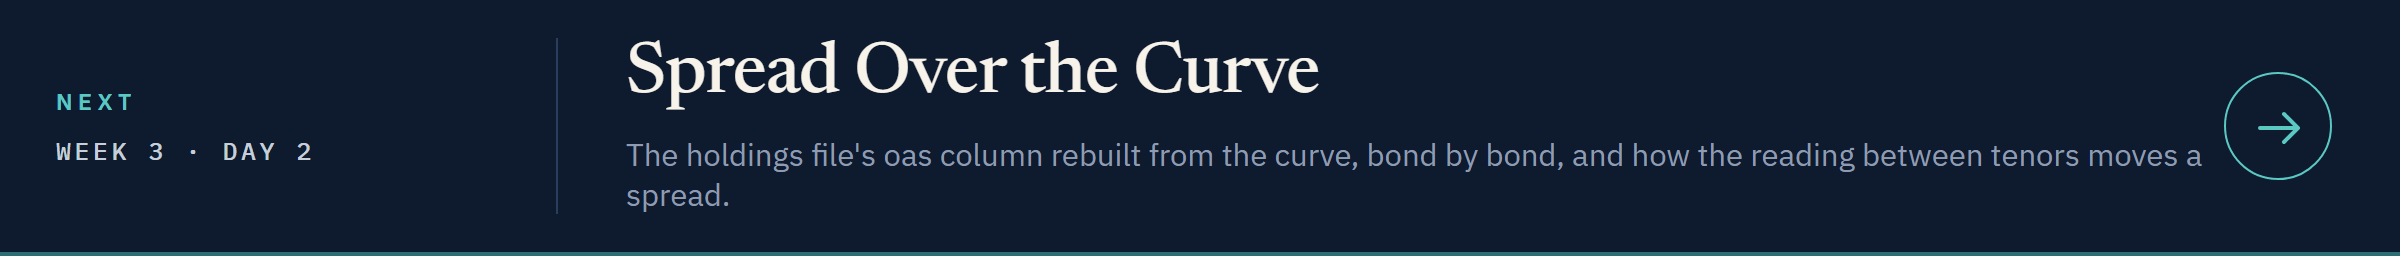](../day2/12_spread_over_the_curve.ipynb)

[Open Day 2 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week3/day2/12_spread_over_the_curve.ipynb)